# EcoMaps · Entrenamiento del clasificador de residuos

Aprendizaje por transferencia con **MobileNetV2** sobre TrashNet, exportado a **TensorFlow.js** para correrlo en el navegador (RF-01, RF-08).

**Clases (RF-01, las 6 del documento técnico):** `metal`, `papel_carton`, `plastico`, `vidrio`, `organico`, `no_aprovechable`.
**Datos:** hasta 600 imágenes de entrenamiento y 60 de prueba por clase (TrashNet no tiene orgánicos y `trash` tiene pocas imágenes: ver la carpeta `fotos_propias`). Las de prueba nunca se usan para entrenar.

**Cómo usarlo en Google Colab**
1. Menú *Entorno de ejecución → Cambiar tipo de entorno → GPU* (más rápido).
2. *Entorno de ejecución → Ejecutar todas*. Si Colab pide reiniciar tras instalar las librerías, reinicia y vuelve a ejecutar todo.
3. Al final se descarga `modelo_v1.zip`: descomprímelo en `app/static/modelo/v1/` del proyecto.

In [1]:
# Keras 2 (tf_keras): el exportador a TensorFlow.js lo necesita. Debe ir ANTES de importar TensorFlow.
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

In [2]:
%pip install -q tf_keras tensorflowjs datasets pillow scikit-learn huggingface_hub
# tensorflowjs deja instalada una versión vieja de `packaging` que rompe otras librerías: se restaura.
%pip install -q -U "packaging>=23"

Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipykernel 7.3.0 requires packaging>=22, but you have packaging 20.9 which is incompatible.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflowjs 3.18.0 requires packaging~=20.9, but you have packaging 26.3 which is incompatible.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import json, random, shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tf_keras as keras
from tf_keras import layers

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); tf.random.set_seed(SEMILLA)

# Clase de TrashNet -> clase de EcoMaps
# 'trash' (lo que no se recicla) pasa a ser la clase «no aprovechable» (caneca negra).
MAPA = {"plastic": "plastico", "glass": "vidrio", "metal": "metal",
        "paper": "papel_carton", "cardboard": "papel_carton", "trash": "no_aprovechable"}
CLASES_EXTRA = {"organico"}   # TrashNet no la trae: sale solo de las fotos propias
N_ENTRENAMIENTO, N_PRUEBA = 600, 60   # tope de fotos de entrenamiento por clase (antes 300)
IMG, LOTE = 224, 16
LADO_MAX = 512
DATA = Path("dataset")
UMBRAL = 0.70  # RF-04: por debajo, la página le pregunta al usuario

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow 2.21.0 | GPU: []


## 0. Fotos de orgánicos (opcional pero necesario para las 6 clases)
TrashNet no trae orgánicos. Esta celda descarga **RealWaste** (UCI Machine Learning Repository, licencia **CC BY 4.0**) y copia sus carpetas *Food Organics* (restos de comida) y *Vegetation* (hojas y plantas) a `fotos_propias/organico/`. El cuaderno las mezcla solo con TrashNet en el siguiente paso.

Son fotos tomadas en un relleno sanitario, no en un hogar: sirven para empezar, pero conviene **sumar tus propias fotos** de cáscaras y restos de comida en `fotos_propias/organico/` (el documento pide al menos 80). Si ya tienes esa carpeta con fotos tuyas, la celda las respeta y solo agrega las de RealWaste.

**Cita (inclúyela en el informe):** Single, S., Iranmanesh, S., & Raad, R. (2023). *RealWaste* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5SS4G

In [4]:
import urllib.request, zipfile, shutil
from pathlib import Path

URL_REALWASTE = "https://archive.ics.uci.edu/static/public/908/realwaste.zip"
CARPETAS_ORGANICO = {"Food Organics", "Vegetation"}
EXT_IMG = {".jpg", ".jpeg", ".png", ".webp"}
destino = Path("fotos_propias") / "organico"
destino.mkdir(parents=True, exist_ok=True)

if any(destino.glob("realwaste_*")):
    print("Ya están las fotos de RealWaste en", destino)
else:
    zip_path = Path("realwaste.zip")
    if not zip_path.exists():
        print("Descargando RealWaste (unos 650 MB, puede tardar unos minutos)…")
        try:
            urllib.request.urlretrieve(URL_REALWASTE, zip_path)
        except Exception as e:
            raise SystemExit(f"No se pudo descargar ({e}).\n"
                             "Descarga realwaste.zip a mano desde https://archive.ics.uci.edu/dataset/908/realwaste, "
                             "súbelo a este mismo panel de archivos y ejecuta esta celda de nuevo.")
    copiadas = 0
    with zipfile.ZipFile(zip_path) as z:
        for nombre in z.namelist():
            partes = Path(nombre).parts
            clase = next((c for c in CARPETAS_ORGANICO if c in partes), None)
            if clase is None or Path(nombre).suffix.lower() not in EXT_IMG:
                continue
            salida = destino / f"realwaste_{clase.replace(' ', '_').lower()}_{Path(nombre).name}"
            with z.open(nombre) as origen, open(salida, "wb") as f:
                shutil.copyfileobj(origen, f)
            copiadas += 1
    print(f"{copiadas} imágenes de RealWaste copiadas a {destino}")
print("Total en fotos_propias/organico:", len(list(destino.iterdir())))

Descargando RealWaste (unos 650 MB, puede tardar unos minutos)…
847 imágenes de RealWaste copiadas a fotos_propias\organico
Total en fotos_propias/organico: 847


## 1. Dataset
Se descarga TrashNet de Hugging Face (Colab tiene internet) y se arma el reparto entrenamiento/prueba.
**Fotos propias (orgánicos y residuos de Montería):** crea una carpeta `fotos_propias/` junto al cuaderno (en Colab, en el panel de archivos) con una subcarpeta por clase (`organico`, `plastico`, `vidrio`, `papel_carton`, `metal`, `no_aprovechable`) y pon ahí tus fotos. Se mezclan con TrashNet y se reparten igual entre entrenamiento y prueba. El documento pide al menos 80 fotos de orgánicos y 30 propias por clase. Si la carpeta no existe, se ignora.

**Para mejorar `no_aprovechable`** (la clase que más se confunde): agrega 60–100 fotos a `fotos_propias/no_aprovechable/` de cajas de pizza con grasa, servilletas y pañuelos usados, toallitas húmedas, icopor, empaques de papas o dulces, papel higiénico sucio y bolsas de basura. Con fondos y luz variados, y **sin repetir las fotos que usas para evaluar en la página**: pon esas en una carpeta `evaluar/` junto al cuaderno (con una subcarpeta por material) y el cuaderno descarta automáticamente cualquier foto de entrenamiento que sea igual o muy parecida a una de ahí.

Si prefieres usar tu propia carpeta o un enlace distinto, cambia `ORIGEN_LOCAL` (carpeta con subcarpetas `cardboard`, `glass`, `metal`, `paper`, `plastic`, `trash`) o el nombre del dataset en la celda.

In [5]:
# El cargador de Hugging Face (load_dataset) falla con las versiones nuevas de `datasets`
# ("Invalid string class label trashnet@..."). Se baja el zip directamente y se usa ORIGEN_LOCAL.
import zipfile
from huggingface_hub import snapshot_download

ruta = snapshot_download("garythung/trashnet", repo_type="dataset", allow_patterns=["*resized*"])
for z in Path(ruta).rglob("dataset-resized.zip"):
    zipfile.ZipFile(z).extractall("trashnet_raw")
ORIGEN_LOCAL = str(next(Path("trashnet_raw").rglob("cardboard")).parent)
print("Dataset en:", ORIGEN_LOCAL)
DATASET_HF = "garythung/trashnet"  # solo se usa si ORIGEN_LOCAL queda en None
FOTOS_PROPIAS = Path("fotos_propias")  # opcional: fotos de orgánicos y de Montería
# Fotos con las que evalúas en la página (carpeta «evaluar» o «fotos_prueba_web»): el modelo NUNCA entrena con ellas.
PRUEBA_EXTERNA = next((p for p in (Path("evaluar"), Path("fotos_prueba_web")) if p.exists()), Path("evaluar"))
UMBRAL_REPETIDA = 10   # distancia máxima entre huellas (de 64 bits) para considerar que es la misma foto

from PIL import ImageOps
EXT = {".jpg", ".jpeg", ".png", ".webp"}
def huella(p):
    """Huella visual de 64 bits (dHash): reconoce la misma foto aunque esté recomprimida o reducida (p. ej. por WhatsApp)."""
    im = ImageOps.exif_transpose(Image.open(p)).convert("L").resize((9, 8), Image.LANCZOS)
    a = np.asarray(im, dtype=int)
    return int("".join("1" if b else "0" for b in (a[:, :-1] > a[:, 1:]).flatten()), 2)

from PIL import Image

def reunir():
    """Devuelve {clase_ecomaps: [imagen PIL o ruta, ...]}."""
    grupos = {c: [] for c in sorted(set(MAPA.values()) | CLASES_EXTRA)}
    if ORIGEN_LOCAL:
        for sub in Path(ORIGEN_LOCAL).iterdir():
            clase = MAPA.get(sub.name.lower())
            if clase and sub.is_dir():
                grupos[clase] += [p for p in sub.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}]
    else:
        from datasets import load_dataset
        ds = load_dataset(DATASET_HF)          # igual que en Hugging Face: devuelve un DatasetDict
        print(ds)
        ds = ds["train"] if "train" in ds else ds[list(ds.keys())[0]]
        nombres = ds.features["label"].names
        print("Etiquetas originales:", nombres)
        etiquetas = ds["label"]  # solo las etiquetas: no decodifica todas las imágenes
        for i, e in enumerate(etiquetas):
            clase = MAPA.get(nombres[e].lower())
            if clase:
                grupos[clase].append(i)
        grupos = {c: [(ds, i) for i in idx] for c, idx in grupos.items()}
    # Fotos propias: fotos_propias/<clase>/*.jpg (clases válidas: las de MAPA y organico)
    vistas, descartadas = set(), 0
    huellas_prueba = []
    if PRUEBA_EXTERNA.exists():
        huellas_prueba = [huella(p) for p in PRUEBA_EXTERNA.rglob("*") if p.suffix.lower() in EXT]
        print(f"Carpeta de evaluación «{PRUEBA_EXTERNA}»: {len(huellas_prueba)} fotos (el modelo no entrenará con ellas).")
    else:
        print("AVISO: no encontré la carpeta «evaluar»; no se pudo comprobar si hay fotos repetidas de evaluación.")
    if FOTOS_PROPIAS.exists():
        for sub in FOTOS_PROPIAS.iterdir():
            if sub.is_dir() and sub.name in grupos:
                for p in sub.iterdir():
                    if p.suffix.lower() not in EXT:
                        continue
                    try:
                        h = huella(p)
                    except Exception:
                        continue                # archivo que no se puede abrir
                    if h in vistas or any(bin(h ^ q).count("1") <= UMBRAL_REPETIDA for q in huellas_prueba):
                        descartadas += 1        # repetida, o igual a una foto de evaluación
                        continue
                    vistas.add(h)
                    grupos[sub.name].append(p)
        if descartadas:
            print(f"Se descartaron {descartadas} fotos propias repetidas o iguales a las de evaluación.")
    return grupos

def abrir(item):
    if isinstance(item, tuple):            # (dataset HF, índice)
        return item[0][item[1]]["image"]
    return Image.open(item)

if DATA.exists():
    shutil.rmtree(DATA)
grupos = reunir()
rnd = random.Random(SEMILLA)
for clase, items in sorted(grupos.items()):
    if not items:
        print(f"AVISO: no hay imágenes para «{clase}». Súbelas a fotos_propias/{clase}/ y ejecuta esta celda de nuevo.")
        continue
    rnd.shuffle(items)
    n_prueba = min(N_PRUEBA, len(items) // 5)
    n_entr = min(N_ENTRENAMIENTO, len(items) - n_prueba)
    reparto = {"prueba": items[:n_prueba], "entrenamiento": items[n_prueba:n_prueba + n_entr]}
    for parte, lista in reparto.items():
        carpeta = DATA / parte / clase
        carpeta.mkdir(parents=True, exist_ok=True)
        for k, it in enumerate(lista):
            im = abrir(it).convert("RGB")
            im.thumbnail((LADO_MAX, LADO_MAX))
            im.save(carpeta / f"{clase}_{k:03d}.jpg", quality=85)
    print(f"{clase}: {n_entr} entrenamiento + {n_prueba} prueba (disponibles: {len(items)})")

c:\Users\Eileen\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]c:\Users\Eileen\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Eileen\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mod

Dataset en: trashnet_raw\dataset-resized
AVISO: no encontré la carpeta «evaluar»; no se pudo comprobar si hay fotos repetidas de evaluación.
metal: 350 entrenamiento + 60 prueba (disponibles: 410)
no_aprovechable: 128 entrenamiento + 31 prueba (disponibles: 159)
organico: 600 entrenamiento + 60 prueba (disponibles: 847)
papel_carton: 600 entrenamiento + 60 prueba (disponibles: 997)
plastico: 422 entrenamiento + 60 prueba (disponibles: 482)
vidrio: 441 entrenamiento + 60 prueba (disponibles: 501)


## 2. Datos para Keras
El aumento de datos (giros, zoom, contraste) solo se aplica al entrenar. El 15 % del entrenamiento se separa para validar.

In [6]:
comunes = dict(image_size=(IMG, IMG), batch_size=LOTE, label_mode="categorical", seed=SEMILLA)
train_raw = keras.utils.image_dataset_from_directory(DATA / "entrenamiento", validation_split=0.15, subset="training", **comunes)
val_raw   = keras.utils.image_dataset_from_directory(DATA / "entrenamiento", validation_split=0.15, subset="validation", **comunes)
test_raw  = keras.utils.image_dataset_from_directory(DATA / "prueba", shuffle=False, **comunes)
CLASES = train_raw.class_names           # orden alfabético; se guarda en metadata.json
print("Clases:", CLASES)

prep = keras.applications.mobilenet_v2.preprocess_input   # escala a [-1, 1]; la página hace lo mismo
aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
])
AUTO = tf.data.AUTOTUNE
train = train_raw.map(lambda x, y: (prep(aumento(x, training=True)), y), num_parallel_calls=AUTO).prefetch(AUTO)
val   = val_raw.map(lambda x, y: (prep(x), y), num_parallel_calls=AUTO).prefetch(AUTO)
test  = test_raw.map(lambda x, y: (prep(x), y), num_parallel_calls=AUTO).prefetch(AUTO)

Found 2541 files belonging to 6 classes.
Using 2160 files for training.
Found 2541 files belonging to 6 classes.
Using 381 files for validation.
Found 331 files belonging to 6 classes.
Clases: ['metal', 'no_aprovechable', 'organico', 'papel_carton', 'plastico', 'vidrio']



## 3. Modelo (transferencia desde MobileNetV2)
Primero se entrena solo la capa final; luego se afinan las últimas capas de MobileNetV2 con una tasa de aprendizaje baja.

In [7]:
base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
base.trainable = False

entrada = keras.Input((IMG, IMG, 3))
x = base(entrada, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation="relu")(x)   # misma cabeza que el modelo que ya está en la app (la versión simple rindió peor)
x = layers.Dropout(0.3)(x)
salida = layers.Dense(len(CLASES), activation="softmax")(x)
modelo = keras.Model(entrada, salida)

# Pesos por clase: las clases con menos fotos (p. ej. no_aprovechable) pesan más al entrenar.
conteo = {c: len(list((DATA / "entrenamiento" / c).glob("*.jpg"))) for c in CLASES}
total_entr = sum(conteo.values())
PESOS = {i: total_entr / (len(CLASES) * conteo[c]) for i, c in enumerate(CLASES)}
print("Fotos de entrenamiento por clase:", conteo)
print("Pesos:", {c: round(PESOS[i], 2) for i, c in enumerate(CLASES)})

alto = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True)

modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
h1 = modelo.fit(train, validation_data=val, epochs=15, callbacks=[alto], class_weight=PESOS)

# Ajuste fino: se liberan las últimas 30 capas de MobileNetV2
base.trainable = True
for capa in base.layers[:-30]:
    capa.trainable = False
modelo.compile(optimizer=keras.optimizers.Adam(1e-5), loss="categorical_crossentropy", metrics=["accuracy"])
h2 = modelo.fit(train, validation_data=val, epochs=10, callbacks=[alto], class_weight=PESOS)


9406464/9406464 [==============================] - 1s 0us/step
Fotos de entrenamiento por clase: {'metal': 350, 'no_aprovechable': 128, 'organico': 600, 'papel_carton': 600, 'plastico': 422, 'vidrio': 441}
Pesos: {'metal': 1.21, 'no_aprovechable': 3.31, 'organico': 0.71, 'papel_carton': 0.71, 'plastico': 1.0, 'vidrio': 0.96}
Epoch 1/15


135/135 [==============================] - 25s 163ms/step - loss: 1.0485 - accuracy: 0.6838 - val_loss: 0.4816 - val_accuracy: 0.8031
Epoch 2/15
135/135 [==============================] - 70s 517ms/step - loss: 0.6599 - accuracy: 0.7898 - val_loss: 0.3547 - val_accuracy: 0.8688
Epoch 3/15
135/135 [==============================] - 61s 436ms/step - loss: 0.5485 - accuracy: 0.8125 - val_loss: 0.4047 - val_accuracy: 0.8346
Epoch 4/15
135/135 [==============================] - 23s 166ms/step - loss: 0.4722 - accuracy: 0.8380 - val_loss: 0.3708 - val_accuracy: 0.8530
Epoch 5/15
135/135 [==============================] - 23s 168ms/step - loss: 0.4265 - accu

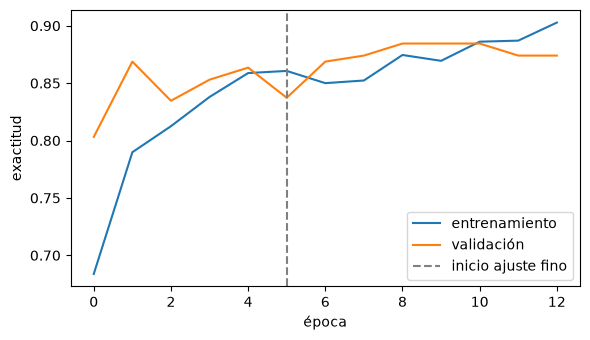

In [8]:
acc = h1.history["accuracy"] + h2.history["accuracy"]
vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
plt.figure(figsize=(6, 3.5))
plt.plot(acc, label="entrenamiento"); plt.plot(vacc, label="validación")
plt.axvline(len(h1.history["accuracy"]) - 1, ls="--", c="gray", label="inicio ajuste fino")
plt.xlabel("época"); plt.ylabel("exactitud"); plt.legend(); plt.tight_layout()
plt.savefig("curvas_entrenamiento.png", dpi=150); plt.show()

## 4. Evaluación con las imágenes de prueba (RF-08)
Estas imágenes no se usaron para entrenar. Meta orientativa: exactitud ≥ 80 %.

21/21 [==============================] - 3s 112ms/step
Exactitud global: 84.6%  (280 de 331 imágenes de prueba)

                 precision    recall  f1-score   support

          metal      0.877     0.833     0.855        60
no_aprovechable      0.793     0.742     0.767        31
       organico      0.984     1.000     0.992        60
   papel_carton      0.914     0.883     0.898        60
       plastico      0.759     0.733     0.746        60
         vidrio      0.735     0.833     0.781        60

       accuracy                          0.846       331
      macro avg      0.844     0.838     0.840       331
   weighted avg      0.848     0.846     0.846       331



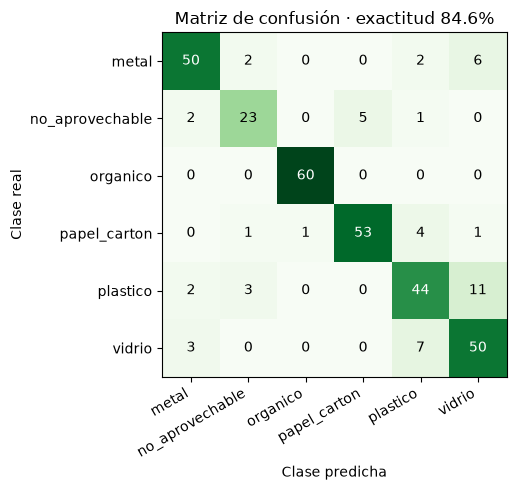

Confusiones más frecuentes (real -> predicha): [('plastico', 'vidrio', 11), ('vidrio', 'plastico', 7), ('metal', 'vidrio', 6), ('no_aprovechable', 'papel_carton', 5), ('papel_carton', 'plastico', 4)]
Predicciones con confianza < 70% (la página pregunta al usuario): 19.0%


In [9]:
from sklearn.metrics import confusion_matrix, classification_report

y_true = np.concatenate([y.numpy().argmax(1) for _, y in test])
probs = modelo.predict(test)
y_pred = probs.argmax(1)
exactitud = float((y_true == y_pred).mean())
print(f"Exactitud global: {exactitud:.1%}  ({int((y_true == y_pred).sum())} de {len(y_true)} imágenes de prueba)\n")
print(classification_report(y_true, y_pred, target_names=CLASES, digits=3))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(cm, cmap="Greens")
ax.set_xticks(range(len(CLASES))); ax.set_xticklabels(CLASES, rotation=30, ha="right")
ax.set_yticks(range(len(CLASES))); ax.set_yticklabels(CLASES)
ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real"); ax.set_title(f"Matriz de confusión · exactitud {exactitud:.1%}")
for i in range(len(CLASES)):
    for j in range(len(CLASES)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.savefig("matriz_confusion.png", dpi=150); plt.show()

# Pares que más se confunden (para el informe: qué se hizo para mejorarlos)
confusiones = [(CLASES[i], CLASES[j], int(cm[i, j])) for i in range(len(CLASES)) for j in range(len(CLASES)) if i != j and cm[i, j] > 0]
confusiones.sort(key=lambda t: -t[2])
print("Confusiones más frecuentes (real -> predicha):", confusiones[:5])

# Cuántas predicciones quedarían bajo el umbral y la página preguntaría al usuario
dudosas = float((probs.max(1) < UMBRAL).mean())
print(f"Predicciones con confianza < {UMBRAL:.0%} (la página pregunta al usuario): {dudosas:.1%}")

json.dump({"exactitud": exactitud, "clases": CLASES, "matriz_confusion": cm.tolist(),
           "imagenes_prueba": int(len(y_true)), "confusiones_top": confusiones[:5], "pct_bajo_umbral": dudosas},
          open("informe_evaluacion.json", "w"), indent=2, ensure_ascii=False)

### Diagnóstico: fotos de la página
Compara el modelo de Keras con el resultado de la página «Evaluar el modelo».

In [10]:
# Diagnóstico: evalúa con el modelo de Keras las MISMAS fotos que usas en la página (carpeta «evaluar»).
# Acepta nombres de carpeta como «papel y carton» o «no aprovechable». Si el resultado es parecido al de la página,
# el modelo es el mismo y la diferencia viene del tipo de fotos. Cópialo a la app solo si supera al modelo actual.
import unicodedata
from PIL import ImageOps

def clase_de(nombre):
    n = unicodedata.normalize("NFD", nombre).encode("ascii", "ignore").decode().lower().strip()
    return n.replace(" y ", "_").replace(" ", "_")

ok = tot = 0
for sub in sorted(p for p in PRUEBA_EXTERNA.rglob("*") if p.is_dir()):
    clase = clase_de(sub.name)
    if clase not in CLASES:
        continue
    a = n = 0
    for f in sub.iterdir():
        if f.suffix.lower() not in EXT:
            continue
        im = ImageOps.exif_transpose(Image.open(f)).convert("RGB").resize((IMG, IMG))   # como hace el navegador
        pred = modelo.predict(prep(np.array(im, dtype="float32"))[None], verbose=0)[0].argmax()
        a += int(CLASES[pred] == clase); n += 1
    ok += a; tot += n
    print(f"{clase}: {a} de {n} ({a / max(n, 1):.0%})")
print(f"\nExactitud con las fotos de la página: {ok / max(tot, 1):.1%} ({ok} de {tot})")



Exactitud con las fotos de la página: 0.0% (0 de 0)


## 5. Exportar a TensorFlow.js
Genera `model.json`, los archivos `.bin` y `metadata.json` (con el nombre de cada clase, en el mismo orden que usa el modelo).

In [11]:
import sys, types
import numpy as np

# Copia de seguridad del modelo entrenado
modelo.save("modelo_respaldo.h5")

# 1) tensorflowjs usa alias de NumPy que ya no existen
for _n, _t in {"object": object, "bool": bool, "int": int, "float": float, "complex": complex, "str": str}.items():
    if not hasattr(np, _n):
        setattr(np, _n, _t)

# 2) tensorflow_hub (que carga tensorflowjs) usa tf.estimator, ya eliminado. Para convertir
#    un modelo de Keras no hace falta: se reemplaza por un módulo vacío.
for _k in [k for k in sys.modules if k.startswith(("tensorflowjs", "tensorflow_hub"))]:
    del sys.modules[_k]          # limpia un intento fallido anterior
sys.modules["tensorflow_hub"] = types.ModuleType("tensorflow_hub")

import tensorflowjs as tfjs

SALIDA = Path("modelo_v1")
if SALIDA.exists():
    shutil.rmtree(SALIDA)
tfjs.converters.save_keras_model(modelo, str(SALIDA))
json.dump({"labels": CLASES, "imageSize": IMG, "preprocess": "x/127.5 - 1", "umbral": UMBRAL, "version": "v1"},
          open(SALIDA / "metadata.json", "w"), indent=2, ensure_ascii=False)

print("Archivos exportados:")
for f in sorted(SALIDA.iterdir()):
    print(f"  {f.name}  {f.stat().st_size / 1e6:.2f} MB")

shutil.make_archive("modelo_v1", "zip", SALIDA)

c:\Users\Eileen\AppData\Local\Programs\Python\Python312\Lib\site-packages\tf_keras\src\engine\training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(
C:\Users\Eileen\AppData\Local\Temp\ipykernel_24284\749990970.py:9: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, _n):
C:\Users\Eileen\AppData\Local\Temp\ipykernel_24284\749990970.py:9: FutureWarning: In the future `np.str` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, _n):


Archivos exportados:
  group1-shard1of3.bin  4.19 MB
  group1-shard2of3.bin  4.19 MB
  group1-shard3of3.bin  1.96 MB
  metadata.json  0.00 MB
  model.json  0.12 MB


'c:\\Users\\Eileen\\Documents\\6TO SEMESTRE\\DESARROLLO SOSTENIBLE\\ECOMAPS\\ml\\modelo_v1.zip'

In [12]:
# Descarga el modelo y los resultados (en Colab). Descomprime modelo_v1.zip en app/static/modelo/v1/
try:
    from google.colab import files
    for f in ["modelo_v1.zip", "matriz_confusion.png", "informe_evaluacion.json", "curvas_entrenamiento.png"]:
        files.download(f)
except ImportError:
    print("Fuera de Colab: los archivos quedaron en la carpeta actual.")

Fuera de Colab: los archivos quedaron en la carpeta actual.


## 6. Prueba con una imagen nueva (opcional)
Sube una foto de un residuo y mira qué responde, con la misma regla de la página: si la confianza es menor al 70 %, muestra las 2 opciones más probables.

In [13]:
from google.colab import files
subida = files.upload()
for nombre in subida:
    im = Image.open(nombre).convert("RGB").resize((IMG, IMG))
    x = prep(np.array(im, dtype="float32"))[None]
    p = modelo.predict(x, verbose=0)[0]
    orden = p.argsort()[::-1]
    if p[orden[0]] >= UMBRAL:
        print(f"{nombre}: {CLASES[orden[0]]} ({p[orden[0]]:.0%})")
    else:
        print(f"{nombre}: no estoy seguro -> {CLASES[orden[0]]} ({p[orden[0]]:.0%}) o {CLASES[orden[1]]} ({p[orden[1]]:.0%})")
    plt.imshow(im); plt.axis("off"); plt.show()

ModuleNotFoundError: No module named 'google.colab'